# 03 — Provider Variation and Change

## Purpose

This notebook examines provider-level variation in NHS A&E activity, emergency admissions, four-hour breaches, and decision-to-admit waiting pressure across the validated analytical period.

The analysis uses three controlled and independently reconciled DuckDB views:

- `analytics.provider_summary`
- `analytics.provider_change`
- `analytics.provider_pressure`

The notebook does not recreate ingestion, transformation, KPI engineering, or SQL aggregation logic.

## Analytical scope

The notebook covers:

- provider coverage across the 25-month period;
- variation in provider attendance and admission volumes;
- September 2025 to September 2026 provider change;
- analytical eligibility controls;
- provider-name changes;
- four-hour breach variation;
- DTA waiting-pressure variation;
- robust ranking and investigation candidates;
- statistical comparison of eligible and ineligible groups;
- findings, limitations, and final validation.

Provider comparisons are interpreted cautiously because organisations differ in scale, service configuration, case mix, and operational context.


## 1. Imports and configuration

The notebook uses the established project configuration and opens DuckDB in read-only mode.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import mannwhitneyu, spearmanr

from nhs_ae.config import PROJECT_PATHS
from nhs_ae.database.connection import database_connection

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

sns.set_theme(style="whitegrid")


## 2. Database connection and analytical-source gate


In [3]:
database_path = PROJECT_PATHS.database_file

assert database_path.exists(), "DuckDB analytical database is missing."

with database_connection(read_only=True) as connection:
    database_version = connection.execute("SELECT version()").fetchone()

assert database_version is not None

print("PROVIDER ANALYSIS DATABASE GATE: PASS")
print("Database:", database_path)
print("DuckDB version:", database_version[0])


PROVIDER ANALYSIS DATABASE GATE: PASS
Database: C:\nhs_ae_analytics\data\database\nhs_ae.duckdb
DuckDB version: v2.0.0


In [4]:
with database_connection(read_only=True) as connection:
    provider_summary = connection.execute(
        """
        SELECT *
        FROM analytics.provider_summary
        """
    ).df()

    provider_change = connection.execute(
        """
        SELECT *
        FROM analytics.provider_change
        """
    ).df()

    provider_pressure = connection.execute(
        """
        SELECT *
        FROM analytics.provider_pressure
        """
    ).df()


In [5]:
assert provider_summary.shape == (207, 7)
assert provider_change.shape == (188, 16)
assert provider_pressure.shape == (188, 30)

assert provider_summary["org_code"].is_unique
assert provider_change["org_code"].is_unique
assert provider_pressure["org_code"].is_unique

assert provider_summary.isna().sum().sum() == 0

expected_change_keys = set(provider_change["org_code"])
expected_pressure_keys = set(provider_pressure["org_code"])
assert expected_change_keys == expected_pressure_keys

print("PROVIDER ANALYTICAL SOURCES: PASS")
print("Provider summary:", provider_summary.shape)
print("Provider change:", provider_change.shape)
print("Provider pressure:", provider_pressure.shape)
print("Comparison keys aligned:", len(expected_change_keys))


PROVIDER ANALYTICAL SOURCES: PASS
Provider summary: (207, 7)
Provider change: (188, 16)
Provider pressure: (188, 30)
Comparison keys aligned: 188


## 3. Provider coverage across the analytical period

Coverage controls are important because providers do not all contribute the same number of reporting months. Full-period and partial-period providers are therefore distinguished before comparative interpretation.


In [6]:
coverage_summary = (
    provider_summary["months_present"]
    .value_counts()
    .sort_index()
    .rename_axis("months_present")
    .reset_index(name="provider_count")
)

coverage_summary["provider_share_pct"] = (
    coverage_summary["provider_count"]
    / len(provider_summary)
    * 100
)

coverage_summary


,months_present,provider_count,provider_share_pct
0,4,1,0.4831
1,6,3,1.4493
2,7,1,0.4831
3,10,1,0.4831
4,12,1,0.4831
5,13,4,1.9324
6,15,1,0.4831
7,17,3,1.4493
8,19,7,3.3816
9,21,1,0.4831


In [7]:
full_coverage_count = int(
    provider_summary["months_present"].eq(25).sum()
)
partial_coverage_count = len(provider_summary) - full_coverage_count

coverage_gate = pd.DataFrame(
    {
        "coverage_group": ["Full 25-month coverage", "Partial coverage"],
        "provider_count": [full_coverage_count, partial_coverage_count],
        "provider_share_pct": [
            full_coverage_count / len(provider_summary) * 100,
            partial_coverage_count / len(provider_summary) * 100,
        ],
    }
)

coverage_gate


,coverage_group,provider_count,provider_share_pct
0,Full 25-month coverage,181,87.4396
1,Partial coverage,26,12.5604


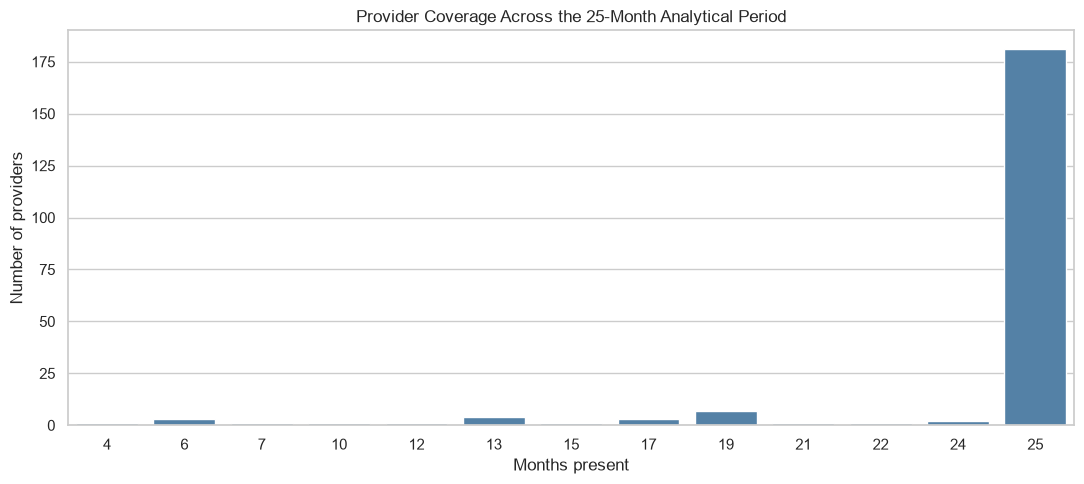

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))

sns.barplot(
    data=coverage_summary,
    x="months_present",
    y="provider_count",
    color="steelblue",
    ax=ax,
)

ax.set_title("Provider Coverage Across the 25-Month Analytical Period")
ax.set_xlabel("Months present")
ax.set_ylabel("Number of providers")

fig.tight_layout()
plt.show()


## 4. Provider activity-volume variation

Provider volumes are highly scale-dependent. Total and average monthly values are therefore assessed together, and rankings are treated as descriptive rather than performance league tables.


In [9]:
provider_volume_summary = provider_summary[
    [
        "total_attendances",
        "average_monthly_attendances",
        "emergency_admissions",
        "average_monthly_admissions",
    ]
].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]).T

provider_volume_summary


,count,mean,std,min,25%,50%,75%,90%,95%,max
total_attendances,207.0000,"282,236.1836","248,537.3371",0.0000,"59,446.0000","232,850.0000","435,469.0000","612,140.2000","750,180.5000","1,124,055.0000"
average_monthly_attendances,207.0000,"11,464.2178","9,838.4839",0.0000,"2,745.0800","9,441.2400","17,418.7600","24,485.6080","30,007.2200","44,962.2000"
emergency_admissions,207.0000,"64,955.1594","71,880.6559",0.0000,0.0000,"52,258.0000","113,443.0000","162,080.0000","181,995.7000","444,273.0000"
average_monthly_admissions,207.0000,"2,607.9745","2,873.6943",0.0000,0.0000,"2,090.3200","4,551.3800","6,483.2000","7,279.8280","17,770.9200"


In [10]:
top_attendance_providers = (
    provider_summary.loc[
        :,
        [
            "org_code",
            "latest_org_name",
            "months_present",
            "total_attendances",
            "average_monthly_attendances",
        ],
    ]
    .sort_values(
        ["total_attendances", "org_code"],
        ascending=[False, True],
    )
    .head(15)
    .reset_index(drop=True)
)

top_attendance_providers


,org_code,latest_org_name,months_present,total_attendances,average_monthly_attendances
0,R0A,MANCHESTER UNIVERSITY NHS FOUNDATION TRUST,25,"1,124,055.0000","44,962.2000"
1,R1H,BARTS HEALTH NHS TRUST,25,"1,115,683.0000","44,627.3200"
2,RAL,ROYAL FREE LONDON NHS FOUNDATION TRUST,25,"1,003,909.0000","40,156.3600"
3,RRK,UNIVERSITY HOSPITALS BIRMINGHAM NHS FOUNDATION...,25,"991,555.0000","39,662.2000"
4,RM3,NORTHERN CARE ALLIANCE NHS FOUNDATION TRUST,25,"881,231.0000","35,249.2400"
5,RDU,FRIMLEY HEALTH NHS FOUNDATION TRUST,25,"880,066.0000","35,202.6400"
6,RAJ,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,25,"875,866.0000","35,034.6400"
7,RYR,UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST,25,"806,625.0000","32,265.0000"
8,RTG,UNIVERSITY HOSPITALS OF DERBY AND BURTON NHS F...,25,"788,426.0000","31,537.0400"
9,RF4,"BARKING, HAVERING AND REDBRIDGE UNIVERSITY HOS...",25,"758,442.0000","30,337.6800"


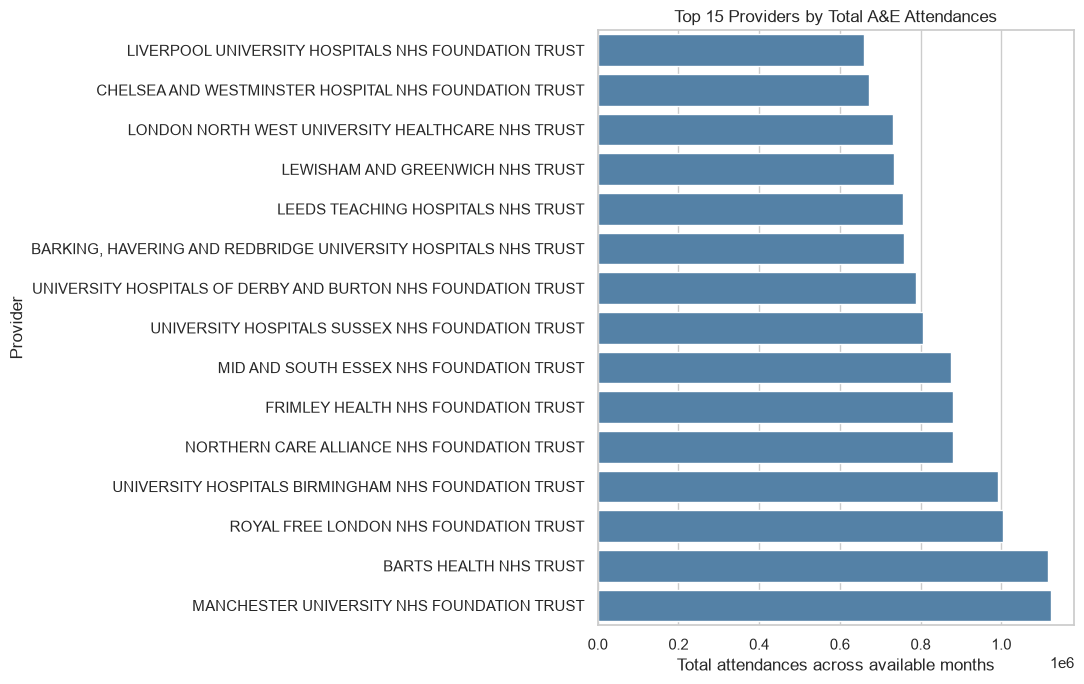

In [11]:
fig, ax = plt.subplots(figsize=(11, 7))

plot_data = top_attendance_providers.sort_values(
    "total_attendances",
    ascending=True,
)

sns.barplot(
    data=plot_data,
    x="total_attendances",
    y="latest_org_name",
    color="steelblue",
    ax=ax,
)

ax.set_title("Top 15 Providers by Total A&E Attendances")
ax.set_xlabel("Total attendances across available months")
ax.set_ylabel("Provider")

fig.tight_layout()
plt.show()


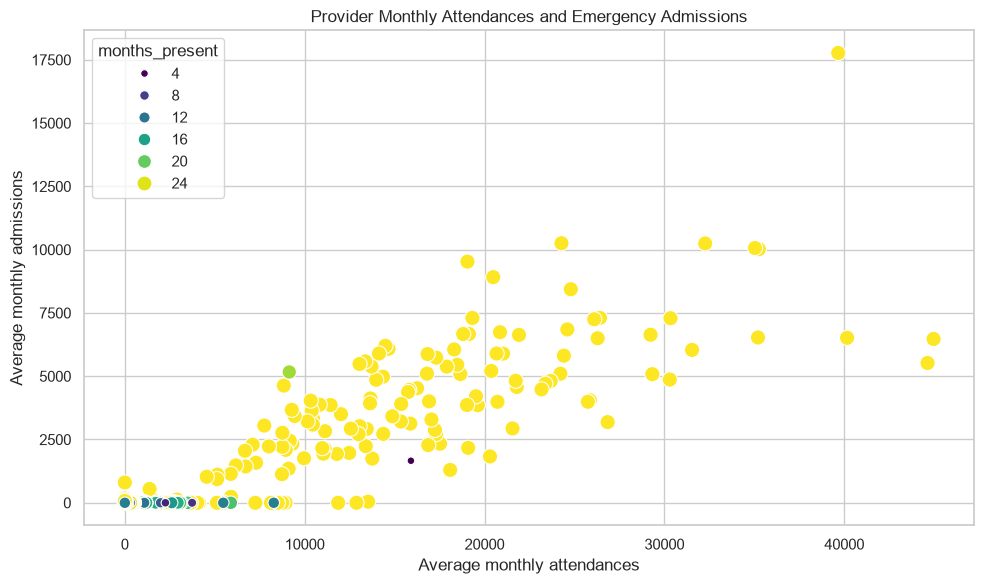

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=provider_summary,
    x="average_monthly_attendances",
    y="average_monthly_admissions",
    hue="months_present",
    palette="viridis",
    size="months_present",
    sizes=(30, 120),
    ax=ax,
)

ax.set_title("Provider Monthly Attendances and Emergency Admissions")
ax.set_xlabel("Average monthly attendances")
ax.set_ylabel("Average monthly admissions")

fig.tight_layout()
plt.show()


## 5. September 2025 to September 2026 provider change

The comparison view contains providers present in both months. Eligibility requires at least 10,000 attendances in each comparison month and full 25-month coverage.


In [13]:
eligibility_summary = pd.DataFrame(
    {
        "measure": [
            "Providers compared",
            "Meet attendance-volume threshold",
            "Full-period coverage",
            "Analysis eligible",
            "Provider name changed",
        ],
        "provider_count": [
            len(provider_change),
            int(provider_change["meets_volume_threshold"].sum()),
            int(provider_change["full_period_coverage"].sum()),
            int(provider_change["analysis_eligible"].sum()),
            int(provider_change["provider_name_changed"].sum()),
        ],
    }
)

eligibility_summary


,measure,provider_count
0,Providers compared,188
1,Meet attendance-volume threshold,99
2,Full-period coverage,181
3,Analysis eligible,99
4,Provider name changed,11


In [14]:
eligible_provider_change = (
    provider_change.loc[
        provider_change["analysis_eligible"]
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(eligible_provider_change) == int(
    provider_change["analysis_eligible"].sum()
)

eligible_change_summary = eligible_provider_change[
    [
        "attendance_percentage_change",
        "admission_percentage_change",
    ]
].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T

eligible_change_summary


,count,mean,std,min,10%,25%,50%,75%,90%,max
attendance_percentage_change,99.0000,0.0857,0.1151,-0.0448,0.0079,0.0411,0.0689,0.0919,0.1203,0.8690
admission_percentage_change,97.0000,0.0133,0.1610,-0.4575,-0.0847,-0.0277,0.0146,0.0575,0.1135,0.9564


In [15]:
attendance_change_extremes = pd.concat(
    [
        eligible_provider_change.nlargest(
            10,
            "attendance_percentage_change",
        ),
        eligible_provider_change.nsmallest(
            10,
            "attendance_percentage_change",
        ),
    ],
    ignore_index=True,
)

attendance_change_extremes = attendance_change_extremes.loc[
    :,
    [
        "org_code",
        "latest_org_name",
        "current_attendances",
        "comparison_attendances",
        "attendance_absolute_change",
        "attendance_percentage_change",
        "provider_name_changed",
    ],
]

attendance_change_extremes["attendance_percentage_change_pct"] = (
    attendance_change_extremes["attendance_percentage_change"] * 100
)

attendance_change_extremes


,org_code,latest_org_name,current_attendances,comparison_attendances,attendance_absolute_change,attendance_percentage_change,provider_name_changed,attendance_percentage_change_pct
0,RX1,NOTTINGHAM UNIVERSITY HOSPITALS NHS TRUST,27799,14874,12925,0.8690,False,86.8966
1,RA7,BRISTOL NHS FOUNDATION TRUST,28667,17943,10724,0.5977,True,59.7670
2,RWW,NORTH CHESHIRE AND MERSEY NHS FOUNDATION TRUST,14041,10080,3961,0.3930,True,39.2956
3,RJ2,LEWISHAM AND GREENWICH NHS TRUST,33723,24392,9331,0.3825,False,38.2543
4,RL4,THE ROYAL WOLVERHAMPTON NHS TRUST,20921,17007,3914,0.2301,False,23.0141
5,RRK,UNIVERSITY HOSPITALS BIRMINGHAM NHS FOUNDATION...,47503,38822,8681,0.2236,False,22.3610
6,RYX,CENTRAL LONDON COMMUNITY HEALTHCARE NHS TRUST,14327,12129,2198,0.1812,False,18.1219
7,RD8,MILTON KEYNES UNIVERSITY HOSPITAL NHS FOUNDATI...,16209,13895,2314,0.1665,False,16.6535
8,RTD,THE NEWCASTLE UPON TYNE HOSPITALS NHS FOUNDATI...,24847,21820,3027,0.1387,False,13.8726
9,RF4,"BARKING, HAVERING AND REDBRIDGE UNIVERSITY HOS...",32810,29271,3539,0.1209,False,12.0905


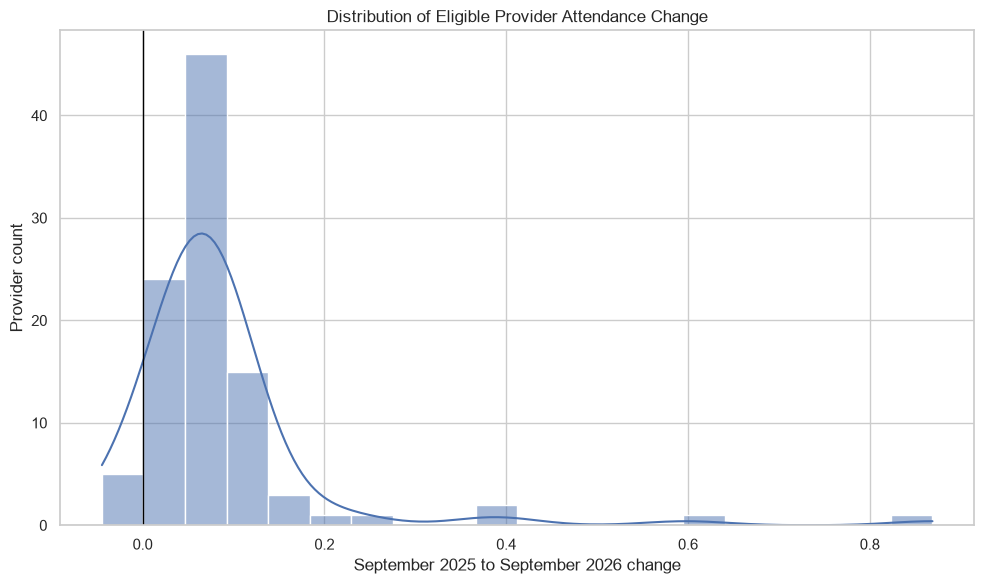

In [16]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    data=eligible_provider_change,
    x="attendance_percentage_change",
    bins=20,
    kde=True,
    ax=ax,
)

ax.axvline(0, color="black", linewidth=1)
ax.set_title("Distribution of Eligible Provider Attendance Change")
ax.set_xlabel("September 2025 to September 2026 change")
ax.set_ylabel("Provider count")

fig.tight_layout()
plt.show()


## 6. Provider-name changes

A name change is a governance flag rather than evidence of a performance change. Flagged providers are retained for interpretation and traceability.


In [17]:
provider_name_changes = (
    provider_change.loc[
        provider_change["provider_name_changed"],
        [
            "org_code",
            "latest_org_name",
            "organisation_name_count",
            "months_present",
            "analysis_eligible",
        ],
    ]
    .sort_values("org_code")
    .reset_index(drop=True)
)

provider_name_changes


,org_code,latest_org_name,organisation_name_count,months_present,analysis_eligible
0,NNJ15,RUTLAND MINOR ILLNESS AND INJURY SERVICE (FORM...,2,25,False
1,RA2,ROYAL SURREY NHS FOUNDATION TRUST,2,25,False
2,RA7,BRISTOL NHS FOUNDATION TRUST,2,25,True
3,RAX,KINGSTON AND RICHMOND NHS FOUNDATION TRUST,2,25,True
4,RHU,PORTSMOUTH HOSPITALS UNIVERSITY NHS TRUST,2,25,True
5,RRF,"WRIGHTINGTON, WIGAN AND LEIGH TEACHING HOSPITA...",2,25,True
6,RW1,HAMPSHIRE AND ISLE OF WIGHT HEALTHCARE NHS FOU...,2,25,False
7,RWD,UNITED LINCOLNSHIRE TEACHING HOSPITALS NHS TRUST,2,25,True
8,RWH,EAST AND NORTH HERTFORDSHIRE TEACHING NHS TRUST,2,25,True
9,RWW,NORTH CHESHIRE AND MERSEY NHS FOUNDATION TRUST,2,25,True


## 7. Provider pressure eligibility

Four-hour breach analysis uses the attendance threshold. DTA analysis uses the emergency-admission threshold. Both also require full-period coverage.


In [18]:
pressure_eligibility_summary = pd.DataFrame(
    {
        "measure": [
            "Providers compared",
            "Meet attendance threshold",
            "Meet admission threshold",
            "Full-period coverage",
            "Breach-analysis eligible",
            "DTA-analysis eligible",
        ],
        "provider_count": [
            len(provider_pressure),
            int(provider_pressure["meets_attendance_threshold"].sum()),
            int(provider_pressure["meets_admission_threshold"].sum()),
            int(provider_pressure["full_period_coverage"].sum()),
            int(provider_pressure["breach_analysis_eligible"].sum()),
            int(provider_pressure["dta_analysis_eligible"].sum()),
        ],
    }
)

pressure_eligibility_summary


,measure,provider_count
0,Providers compared,188
1,Meet attendance threshold,99
2,Meet admission threshold,117
3,Full-period coverage,181
4,Breach-analysis eligible,99
5,DTA-analysis eligible,117


## 8. Four-hour breach variation among eligible providers


In [19]:
breach_eligible = (
    provider_pressure.loc[
        provider_pressure["breach_analysis_eligible"]
    ]
    .copy()
    .reset_index(drop=True)
)

breach_change_summary = breach_eligible[
    [
        "four_hour_breaches_absolute_change",
        "four_hour_breaches_percentage_change",
    ]
].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T

breach_change_summary


,count,mean,std,min,10%,25%,50%,75%,90%,max
four_hour_breaches_absolute_change,99.0000,501.9798,708.8626,"-1,096.0000",-264.0000,23.5000,501.0000,863.0000,"1,226.0000","3,264.0000"
four_hour_breaches_percentage_change,99.0000,0.1415,0.3168,-0.2308,-0.0727,0.0051,0.0981,0.1979,0.2885,2.7328


In [20]:
largest_breach_increases = (
    breach_eligible.nlargest(
        15,
        "four_hour_breaches_absolute_change",
    )
    .loc[
        :,
        [
            "org_code",
            "latest_org_name",
            "current_total_attendances",
            "current_four_hour_breaches",
            "comparison_four_hour_breaches",
            "four_hour_breaches_absolute_change",
            "four_hour_breaches_percentage_change",
        ],
    ]
    .reset_index(drop=True)
)

largest_breach_increases


,org_code,latest_org_name,current_total_attendances,current_four_hour_breaches,comparison_four_hour_breaches,four_hour_breaches_absolute_change,four_hour_breaches_percentage_change
0,RA7,BRISTOL NHS FOUNDATION TRUST,28667,8694,5430,3264,0.6011
1,RAJ,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,37143,11289,8843,2446,0.2766
2,RX1,NOTTINGHAM UNIVERSITY HOSPITALS NHS TRUST,27799,9388,7072,2316,0.3275
3,RJ2,LEWISHAM AND GREENWICH NHS TRUST,33723,9742,7623,2119,0.2780
4,RYR,UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST,33825,13321,11308,2013,0.1780
5,RWF,MAIDSTONE AND TUNBRIDGE WELLS NHS TRUST,23409,5872,4326,1546,0.3574
6,REF,ROYAL CORNWALL HOSPITALS NHS TRUST,19689,4830,3328,1502,0.4513
7,RTG,UNIVERSITY HOSPITALS OF DERBY AND BURTON NHS F...,32437,10533,9136,1397,0.1529
8,RTP,SURREY AND SUSSEX HEALTHCARE NHS TRUST,11041,5288,3916,1372,0.3504
9,RVV,EAST KENT HOSPITALS UNIVERSITY NHS FOUNDATION ...,26960,7529,6227,1302,0.2091


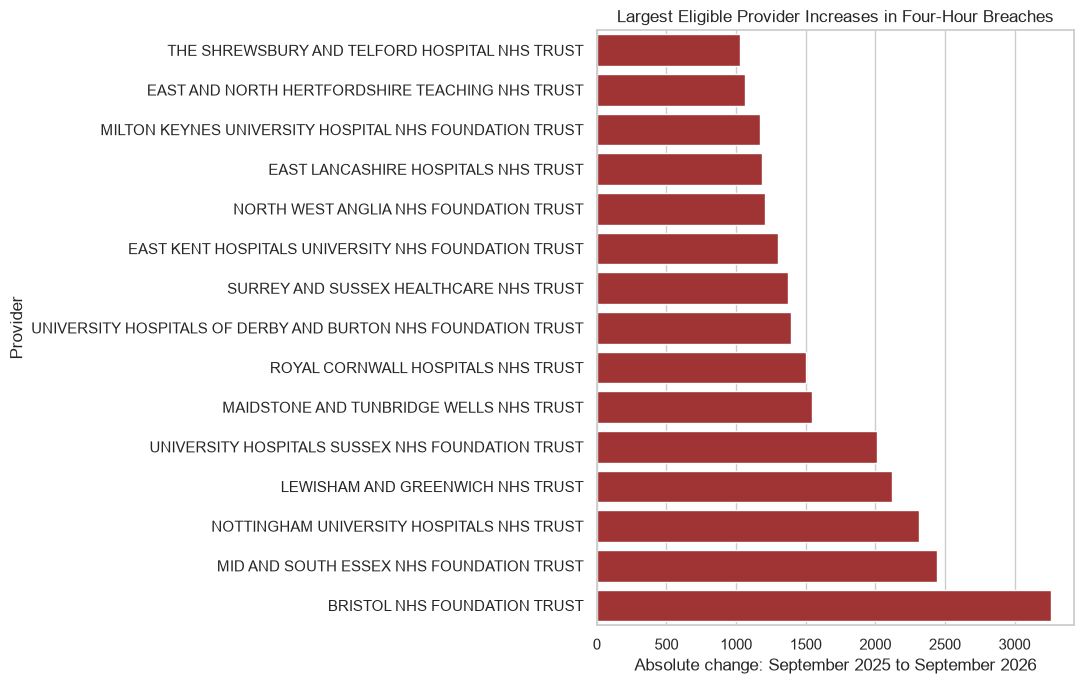

In [21]:
fig, ax = plt.subplots(figsize=(11, 7))

plot_data = largest_breach_increases.sort_values(
    "four_hour_breaches_absolute_change",
    ascending=True,
)

sns.barplot(
    data=plot_data,
    x="four_hour_breaches_absolute_change",
    y="latest_org_name",
    color="firebrick",
    ax=ax,
)

ax.set_title("Largest Eligible Provider Increases in Four-Hour Breaches")
ax.set_xlabel("Absolute change: September 2025 to September 2026")
ax.set_ylabel("Provider")

fig.tight_layout()
plt.show()


## 9. Decision-to-admit pressure variation among eligible providers


In [22]:
dta_eligible = (
    provider_pressure.loc[
        provider_pressure["dta_analysis_eligible"]
    ]
    .copy()
    .reset_index(drop=True)
)

dta_change_summary = dta_eligible[
    [
        "dta_waits_4_12hrs_percentage_change",
        "dta_waits_12plus_hrs_percentage_change",
        "total_dta_waits_4plus_hrs_percentage_change",
    ]
].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T

dta_change_summary


,count,mean,std,min,10%,25%,50%,75%,90%,max
dta_waits_4_12hrs_percentage_change,116.0000,0.0123,0.3752,-0.6373,-0.3245,-0.1988,-0.0322,0.1192,0.2530,2.1658
dta_waits_12plus_hrs_percentage_change,112.0000,1.9383,11.0107,-1.0000,-0.3567,-0.1100,0.0941,0.5791,1.9036,108.0000
total_dta_waits_4plus_hrs_percentage_change,116.0000,0.0830,0.3782,-0.5957,-0.2423,-0.1345,0.0176,0.2098,0.3361,2.6950


In [23]:
largest_long_wait_increases = (
    dta_eligible.nlargest(
        15,
        "dta_waits_12plus_hrs_absolute_change",
    )
    .loc[
        :,
        [
            "org_code",
            "latest_org_name",
            "current_emergency_admissions",
            "current_dta_waits_12plus_hrs",
            "comparison_dta_waits_12plus_hrs",
            "dta_waits_12plus_hrs_absolute_change",
            "dta_waits_12plus_hrs_percentage_change",
        ],
    ]
    .reset_index(drop=True)
)

largest_long_wait_increases


,org_code,latest_org_name,current_emergency_admissions,current_dta_waits_12plus_hrs,comparison_dta_waits_12plus_hrs,dta_waits_12plus_hrs_absolute_change,dta_waits_12plus_hrs_percentage_change
0,RAJ,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,10543,1371,483,888,1.8385
1,RWF,MAIDSTONE AND TUNBRIDGE WELLS NHS TRUST,2905,686,96,590,6.1458
2,RA7,BRISTOL NHS FOUNDATION TRUST,12707,620,213,407,1.9108
3,RWD,UNITED LINCOLNSHIRE TEACHING HOSPITALS NHS TRUST,5984,1347,946,401,0.4239
4,RRK,UNIVERSITY HOSPITALS BIRMINGHAM NHS FOUNDATION...,18799,2085,1692,393,0.2323
5,RMC,BOLTON NHS FOUNDATION TRUST,3289,580,213,367,1.7230
6,RN7,DARTFORD AND GRAVESHAM NHS TRUST,4129,490,129,361,2.7984
7,RX1,NOTTINGHAM UNIVERSITY HOSPITALS NHS TRUST,9104,979,634,345,0.5442
8,RNQ,KETTERING GENERAL HOSPITAL NHS FOUNDATION TRUST,2191,743,438,305,0.6963
9,RDU,FRIMLEY HEALTH NHS FOUNDATION TRUST,6861,599,325,274,0.8431


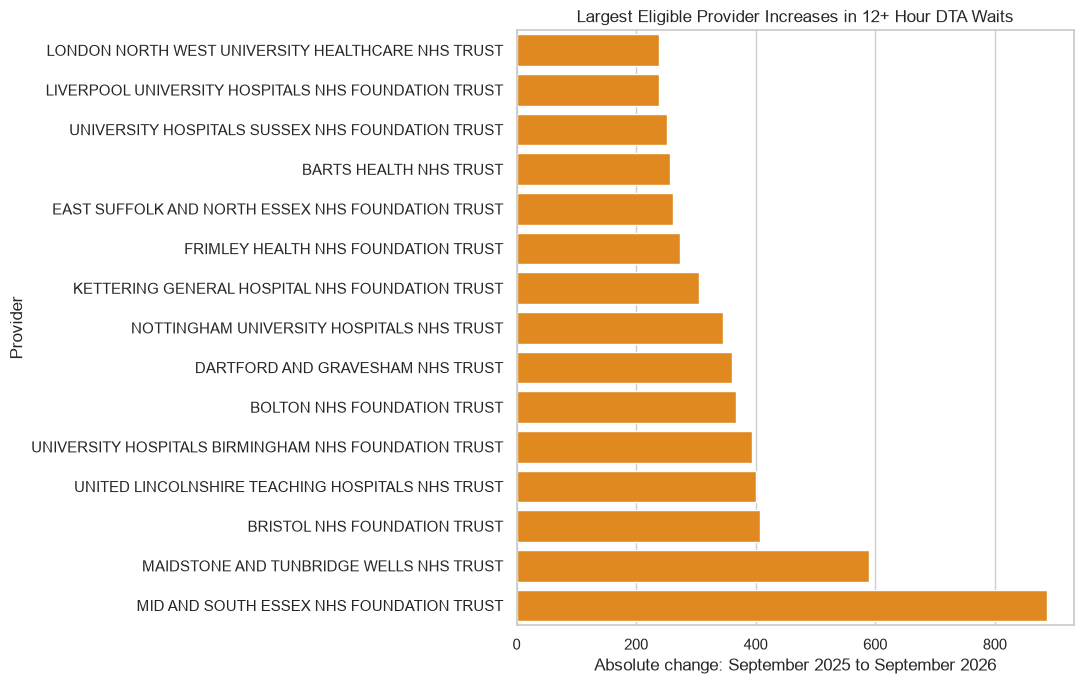

In [24]:
fig, ax = plt.subplots(figsize=(11, 7))

plot_data = largest_long_wait_increases.sort_values(
    "dta_waits_12plus_hrs_absolute_change",
    ascending=True,
)

sns.barplot(
    data=plot_data,
    x="dta_waits_12plus_hrs_absolute_change",
    y="latest_org_name",
    color="darkorange",
    ax=ax,
)

ax.set_title("Largest Eligible Provider Increases in 12+ Hour DTA Waits")
ax.set_xlabel("Absolute change: September 2025 to September 2026")
ax.set_ylabel("Provider")

fig.tight_layout()
plt.show()


## 10. Scale and pressure-change relationships

Spearman correlation is used because provider volumes and changes can be skewed and influenced by extreme organisations. The analysis remains associative rather than causal.


In [26]:
relationship_definitions = [
    (
        "current_total_attendances",
        "four_hour_breaches_absolute_change",
        breach_eligible,
        "Attendance scale vs breach absolute change",
    ),
    (
        "attendance_percentage_change",
        "four_hour_breaches_percentage_change",
        eligible_provider_change.merge(
            breach_eligible[
                [
                    "org_code",
                    "four_hour_breaches_percentage_change",
                ]
            ],
            on="org_code",
            how="inner",
            validate="one_to_one",
        ),
        "Attendance percentage change vs breach percentage change",
    ),
    (
        "current_emergency_admissions",
        "dta_waits_12plus_hrs_absolute_change",
        dta_eligible,
        "Admission scale vs 12+ hour DTA absolute change",
    ),
]

provider_relationship_results = []

for x_column, y_column, frame, relationship in relationship_definitions:
    analysis_frame = frame[[x_column, y_column]].dropna()
    correlation, p_value = spearmanr(
        analysis_frame[x_column],
        analysis_frame[y_column],
    )

    provider_relationship_results.append(
        {
            "relationship": relationship,
            "observations": len(analysis_frame),
            "spearman_correlation": correlation,
            "p_value": p_value,
            "significant_at_0_05": p_value < 0.05,
        }
    )

provider_relationship_tests = pd.DataFrame(
    provider_relationship_results
)

provider_relationship_tests


,relationship,observations,spearman_correlation,p_value,significant_at_0_05
0,Attendance scale vs breach absolute change,99,0.2335,0.0200,True
1,Attendance percentage change vs breach percent...,99,0.3166,0.0014,True
2,Admission scale vs 12+ hour DTA absolute change,117,0.2249,0.0148,True


## 11. Eligible versus ineligible provider comparison

This test checks whether the distribution of attendance percentage change differs between eligible and ineligible comparison providers. The result is descriptive of these groups and should not be interpreted as an effect of eligibility.


In [27]:
eligible_attendance_change = provider_change.loc[
    provider_change["analysis_eligible"],
    "attendance_percentage_change",
].dropna()

ineligible_attendance_change = provider_change.loc[
    ~provider_change["analysis_eligible"],
    "attendance_percentage_change",
].dropna()

mann_whitney = mannwhitneyu(
    eligible_attendance_change,
    ineligible_attendance_change,
    alternative="two-sided",
)

eligibility_group_test = pd.DataFrame(
    {
        "eligible_providers": [len(eligible_attendance_change)],
        "ineligible_providers": [len(ineligible_attendance_change)],
        "eligible_median_change": [eligible_attendance_change.median()],
        "ineligible_median_change": [ineligible_attendance_change.median()],
        "mann_whitney_u": [mann_whitney.statistic],
        "p_value": [mann_whitney.pvalue],
        "significant_at_0_05": [mann_whitney.pvalue < 0.05],
    }
)

eligibility_group_test


,eligible_providers,ineligible_providers,eligible_median_change,ineligible_median_change,mann_whitney_u,p_value,significant_at_0_05
0,99,80,0.0689,0.0575,"4,437.0000",0.1668,False


## 12. Investigation candidates

Candidates are selected using explicit, reproducible rules rather than subjective ranking. A provider is flagged when eligible and in the upper decile of the relevant absolute pressure-change measure.


In [30]:
breach_threshold = breach_eligible[
    "four_hour_breaches_absolute_change"
].quantile(0.90)

dta_threshold = dta_eligible[
    "dta_waits_12plus_hrs_absolute_change"
].quantile(0.90)

candidate_source = provider_pressure.loc[
    :,
    [
        "org_code",
        "latest_org_name",
        "four_hour_breaches_absolute_change",
        "dta_waits_12plus_hrs_absolute_change",
        "breach_analysis_eligible",
        "dta_analysis_eligible",
        "provider_name_changed",
    ],
].copy()

candidate_source["breach_increase_flag"] = (
    candidate_source["breach_analysis_eligible"]
    & (
        candidate_source["four_hour_breaches_absolute_change"]
        >= breach_threshold
    )
)

candidate_source["dta_12plus_increase_flag"] = (
    candidate_source["dta_analysis_eligible"]
    & (
        candidate_source["dta_waits_12plus_hrs_absolute_change"]
        >= dta_threshold
    )
)

investigation_candidates = candidate_source.loc[
    candidate_source["breach_increase_flag"]
    | candidate_source["dta_12plus_increase_flag"]
].copy()

investigation_candidates["investigation_reason"] = np.select(
    [
        investigation_candidates["breach_increase_flag"]
        & investigation_candidates["dta_12plus_increase_flag"],
        investigation_candidates["breach_increase_flag"],
        investigation_candidates["dta_12plus_increase_flag"],
    ],
    [
        "Upper-decile increase in both pressure measures",
        "Upper-decile increase in four-hour breaches",
        "Upper-decile increase in 12+ hour DTA waits",
    ],
    default="Not flagged",
)

investigation_candidates = (
    investigation_candidates[
        [
            "org_code",
            "latest_org_name",
            "four_hour_breaches_absolute_change",
            "dta_waits_12plus_hrs_absolute_change",
            "breach_increase_flag",
            "dta_12plus_increase_flag",
            "provider_name_changed",
            "investigation_reason",
        ]
    ]
    .sort_values(
        [
            "breach_increase_flag",
            "dta_12plus_increase_flag",
            "four_hour_breaches_absolute_change",
            "dta_waits_12plus_hrs_absolute_change",
            "org_code",
        ],
        ascending=[
            False,
            False,
            False,
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)

assert investigation_candidates["org_code"].is_unique
assert investigation_candidates["investigation_reason"].ne(
    "Not flagged"
).all()

investigation_candidates

,org_code,latest_org_name,four_hour_breaches_absolute_change,dta_waits_12plus_hrs_absolute_change,breach_increase_flag,dta_12plus_increase_flag,provider_name_changed,investigation_reason
0,RA7,BRISTOL NHS FOUNDATION TRUST,3264,407,True,True,True,Upper-decile increase in both pressure measures
1,RAJ,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,2446,888,True,True,False,Upper-decile increase in both pressure measures
2,RX1,NOTTINGHAM UNIVERSITY HOSPITALS NHS TRUST,2316,345,True,True,False,Upper-decile increase in both pressure measures
3,RWF,MAIDSTONE AND TUNBRIDGE WELLS NHS TRUST,1546,590,True,True,False,Upper-decile increase in both pressure measures
4,RJ2,LEWISHAM AND GREENWICH NHS TRUST,2119,115,True,False,False,Upper-decile increase in four-hour breaches
5,RYR,UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST,2013,251,True,False,False,Upper-decile increase in four-hour breaches
6,REF,ROYAL CORNWALL HOSPITALS NHS TRUST,1502,-48,True,False,False,Upper-decile increase in four-hour breaches
7,RTG,UNIVERSITY HOSPITALS OF DERBY AND BURTON NHS F...,1397,237,True,False,False,Upper-decile increase in four-hour breaches
8,RTP,SURREY AND SUSSEX HEALTHCARE NHS TRUST,1372,-9,True,False,False,Upper-decile increase in four-hour breaches
9,RVV,EAST KENT HOSPITALS UNIVERSITY NHS FOUNDATION ...,1302,-93,True,False,False,Upper-decile increase in four-hour breaches


## 13. Analytical interpretation guardrails

The provider outputs are screening tools, not league tables.

- Large absolute changes can reflect provider scale.
- Large percentage changes can arise from small denominators.
- Eligibility controls reduce, but do not remove, comparability limitations.
- Provider-name changes require governance review before organisational interpretation.
- Statistical association does not establish operational causation.
- Investigation candidates require local context, data-quality review, and operational evidence.


## 14. Final notebook validation


In [31]:
assert provider_summary.shape == (207, 7)
assert provider_change.shape == (188, 16)
assert provider_pressure.shape == (188, 30)

assert len(coverage_gate) == 2
assert len(eligibility_summary) == 5
assert len(pressure_eligibility_summary) == 6
assert len(provider_relationship_tests) == 3
assert len(eligibility_group_test) == 1

assert eligible_provider_change["analysis_eligible"].all()
assert breach_eligible["breach_analysis_eligible"].all()
assert dta_eligible["dta_analysis_eligible"].all()

assert investigation_candidates["org_code"].is_unique
assert investigation_candidates["org_code"].notna().all()
assert investigation_candidates["latest_org_name"].notna().all()
assert (
    investigation_candidates["breach_increase_flag"]
    | investigation_candidates["dta_12plus_increase_flag"]
).all()

candidate_reason_summary = (
    investigation_candidates["investigation_reason"]
    .value_counts()
    .rename_axis("investigation_reason")
    .reset_index(name="provider_count")
)

print("PROVIDER VARIATION NOTEBOOK VALIDATION: PASS")
print("Provider summary rows:", len(provider_summary))
print("Providers compared:", len(provider_change))
print(
    "Attendance-change eligible:",
    len(eligible_provider_change),
)
print(
    "Breach-analysis eligible:",
    len(breach_eligible),
)
print(
    "DTA-analysis eligible:",
    len(dta_eligible),
)
print(
    "Unique investigation candidates:",
    len(investigation_candidates),
)

candidate_reason_summary

PROVIDER VARIATION NOTEBOOK VALIDATION: PASS
Provider summary rows: 207
Providers compared: 188
Attendance-change eligible: 99
Breach-analysis eligible: 99
DTA-analysis eligible: 117
Unique investigation candidates: 18


,investigation_reason,provider_count
0,Upper-decile increase in 12+ hour DTA waits,8
1,Upper-decile increase in four-hour breaches,6
2,Upper-decile increase in both pressure measures,4


## 15. Key findings template

After executing the notebook, summarise only the calculated results displayed above.

The final narrative should cover:

1. the proportion of providers with full-period coverage;
2. the degree of variation in provider scale;
3. the median and spread of eligible attendance and admission changes;
4. the largest eligible four-hour breach increases;
5. the largest eligible 12-plus-hour DTA increases;
6. whether provider scale and pressure changes are statistically associated;
7. whether eligible and ineligible attendance-change distributions differ;
8. the number and reason for investigation candidates;
9. the effect of provider-name changes on interpretation.

Do not infer operational causes from these data alone.


## 16. Limitations

- Provider organisations differ in size, service mix, case mix, and local operating context.
- Monthly aggregated data cannot explain patient-level pathways or daily operational variation.
- Two-month provider comparison does not represent the full trajectory between the comparison periods.
- Absolute changes are influenced by provider scale; percentage changes are sensitive to denominators.
- Eligibility thresholds are analytical controls, not formal judgements of provider performance.
- Provider-name changes can reflect organisational or reporting changes that require separate governance review.
- Multiple comparisons increase the chance of apparently significant results.
- Statistical associations do not establish causation.
- Investigation candidates are screening outputs and require local validation before use in decision-making.


## 17. Notebook completion

This notebook provides the controlled provider-level variation and change layer for the September 2024 to September 2026 NHS A&E analytical product.

It consumes validated DuckDB views, preserves eligibility and governance controls, and separates descriptive screening from causal interpretation.
